# TP5 · Ejercicio 2: Autoencoder Variacional (VAE) sobre sprites de Pokémon
**Pregunta guía.** El autoencoder del ejercicio 1 reconstruye bien, pero deja **huecos** en el espacio latente: la letra nueva sólo era legible cerca de los códigos de entrenamiento. ¿Qué cambia si obligamos al espacio latente a parecerse a una distribución conocida, $\mathcal{N}(0,I)$? ¿Se puede sacar de ahí un Pokémon que no existe y que igual "parezca un Pokémon"?

**Regla del TP.** Igual que en el ejercicio 1, todo el aprendizaje está escrito a mano con `numpy` (`deep.py`). `PIL` sólo se usa para leer y escalar los sprites, y `matplotlib` para graficar.

| § | Contenido | Consigna |
|---|---|---|
| 1 | Conjunto de datos: 809 sprites de Pokémon | 2a |
| 2 | Del autoencoder al VAE: teoría, implementación y decisiones de arquitectura | 2b |
| 3 | Ablación sobre $\beta$ y el tamaño del latente | 2b |
| 4 | Espacio latente en 2 dimensiones: VAE frente a autoencoder | 2b |
| 5 | Generación de Pokémon nuevos | 2c |
| 6 | Conclusiones y limitaciones | |

**Bibliografía.** Kingma & Welling (2014), *Auto-Encoding Variational Bayes*; Doersch (2016), *Tutorial on Variational Autoencoders*; Kingma & Welling (2019), *An Introduction to Variational Autoencoders*; Higgins et al. (2017), *β-VAE*; Bowman et al. (2016), *Generating Sentences from a Continuous Space* (colapso del posterior); Heusel et al. (2017), *GANs trained by a two time-scale update rule* (distancia de Fréchet); Prince (2023), *Understanding Deep Learning*, cap. 17.

## 1. Conjunto de datos (consigna 2a)

Usamos los **809 sprites** de `data/pokemon/` (generaciones 1 a 7, 120×120). Frente a los emojis que sugiere el enunciado, este conjunto es más exigente y más interesante para un modelo generativo:

- **No hay clases:** cada Pokémon aparece una sola vez. El VAE no puede memorizar "prototipos" por categoría; tiene que aprender qué tienen en común *todos* (una figura centrada, con contorno, colores planos sobre fondo blanco).
- **Es en color:** la entrada tiene 3 canales, así que el modelo también aprende paletas.
- **Generar uno nuevo tiene un criterio claro de éxito:** que no sea ninguno de los 809 y que igual parezca un Pokémon.

**Preprocesamiento** (`datos.cargar_pokemon`):
1. Los PNG traen transparencia y los JPG fondo blanco: todo se compone **sobre blanco**.
2. Se recorta la caja del Pokémon y se centra en un cuadrado con 6 % de margen. Sin este paso, el tamaño del dibujo dependería de cuánto fondo traía cada archivo y el modelo gastaría capacidad en eso.
3. Se escala a **32×32 RGB** (3072 valores en $[0,1]$). Es lo máximo razonable para una MLP en `numpy`: a esta resolución los Pokémon todavía se reconocen.

**Partición.** Se retienen **81 Pokémon completos (10 %)** que el modelo nunca ve, para medir si generaliza a Pokémon nuevos y no sólo si memoriza. Los 728 de entrenamiento se duplican con su **reflejo horizontal** (un Pokémon espejado sigue siendo un Pokémon): 1456 imágenes de entrenamiento.

sprites: (809, 3072) | entrenamiento (con espejados): 1456 | validación (Pokémon no vistos): 81


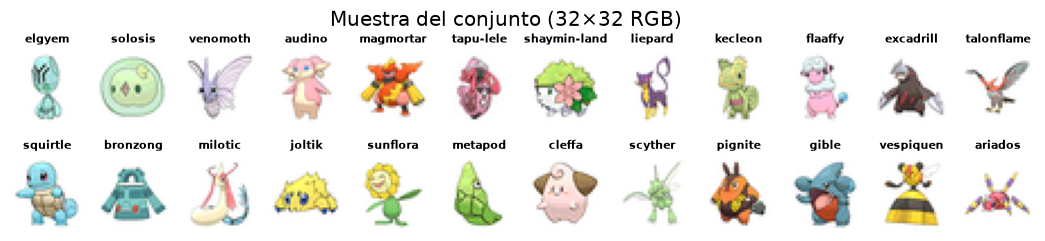

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")   # con matrices de este tamaño, más hilos de BLAS van más lento
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ))
from deep import VAE, bce_from_logits, gradient_check_vae
from experimentos import *
from graficos import *
cfg = cargar_config(); c = cfg["ej2_pokemon"]
RES = RAIZ / "results"
np.random.seed(cfg["semilla_global"])

P = datos_pokemon(cfg)
S, nombres = P["shape"], P["nombres"]
print("sprites:", P["X"].shape, "| entrenamiento (con espejados):", P["Xtr"].shape[0], "| validación (Pokémon no vistos):", P["Xte"].shape[0])
idx = np.random.default_rng(1).choice(len(P["X"]), 24, replace=False)
fig = mostrar_imagenes(P["X"][idx], S, [nombres[i] for i in idx], ncols=12, tam=1.0, ax_title_size=7)
plt.suptitle("Muestra del conjunto (32×32 RGB)", y=1.01); plt.show()

## 2. Del autoencoder al VAE (consigna 2b)

### 2.1 El problema que deja el ejercicio 1
El autoencoder aprende un codificador $z=f_\theta(x)$ y un decodificador $\hat x=g_\phi(z)$ minimizando sólo el error de reconstrucción. **Nada en la pérdida dice dónde tienen que quedar los códigos.** En el ejercicio 1 quedaron entre −4,2 y 7,5, dispersos, y la letra nueva sólo fue legible cerca de ellos: entre los códigos hay regiones que el decodificador nunca vio. Para generar no sabemos de qué distribución sacar $z$.

### 2.2 Modelo generativo y ELBO
El VAE fija esa distribución de antemano. Supone que cada imagen se genera como $z\sim p(z)=\mathcal{N}(0,I)$ y luego $x\sim p_\phi(x\mid z)$, con $p_\phi(x\mid z)=\mathrm{Bernoulli}(g_\phi(z))$ píxel a píxel. Como $\log p_\phi(x)=\log\int p_\phi(x\mid z)p(z)\,dz$ es intratable, el codificador pasa a devolver una **distribución** $q_\theta(z\mid x)=\mathcal{N}(\mu_\theta(x),\mathrm{diag}\,\sigma^2_\theta(x))$ y se maximiza la cota inferior

$$\log p_\phi(x)\;\ge\;\mathrm{ELBO}(x)=\mathbb{E}_{q_\theta(z\mid x)}[\log p_\phi(x\mid z)]-\mathrm{KL}\big(q_\theta(z\mid x)\,\|\,\mathcal{N}(0,I)\big).$$

La pérdida es $-\mathrm{ELBO}$ = **reconstrucción (BCE) + KL**. El término KL es el que resuelve el problema del ejercicio 1: empuja cada $q(z\mid x)$ hacia $\mathcal{N}(0,I)$, así que los códigos cubren el prior sin huecos y **decodificar $z\sim\mathcal{N}(0,I)$ produce imágenes plausibles**.

### 2.3 KL cerrada, reparametrización y $\beta$
Para gaussianas diagonales, $\mathrm{KL}=\tfrac12\sum_j(\mu_j^2+\sigma_j^2-\log\sigma_j^2-1)$. Para derivar a través del muestreo se usa $z=\mu+\sigma\odot\varepsilon$ con $\varepsilon\sim\mathcal{N}(0,I)$: el azar queda en $\varepsilon$ y el gradiente fluye por $\mu$ y $\sigma$. Con un peso $\beta$ en el KL (Higgins et al., 2017), $\beta=1$ es el ELBO exacto y **$\beta=0$ es un autoencoder determinístico** (sin KL la varianza colapsa a 0). Por eso $\beta=0$ es el punto de comparación natural con el ejercicio 1, con la misma arquitectura y los mismos datos.

### 2.4 Qué se extiende del autoencoder del ejercicio 1
`deep.VAE` usa las mismas piezas que `deep.Autoencoder` (capas `MLP`, retropropagación a mano, Adam y BCE estable desde logits). Los cambios son:

| | Autoencoder (ej. 1) | VAE (ej. 2) |
|---|---|---|
| Salida del codificador | un punto $z$ | dos cabezas lineales: $\mu$ y $\log\sigma^2$ |
| Latente | $z=f_\theta(x)$ | $z=\mu+\sigma\odot\varepsilon$ (reparametrización) |
| Pérdida | BCE | BCE + $\beta\cdot$KL |
| Gradiente extra | — | $\partial\mathcal{L}/\partial\mu\mathrel{+}=\beta\mu$, $\ \partial\mathcal{L}/\partial\log\sigma^2\mathrel{+}=\tfrac{\beta}{2}(\sigma^2-1)$ |

El gradiente se verifica con diferencias finitas, fijando $\varepsilon$:

In [2]:
print(f"Error relativo máximo del gradiente del VAE: {gradient_check_vae():.2e}")

Error relativo máximo del gradiente del VAE: 1.82e-08


### 2.5 Arquitectura y decisiones
- **Codificador** $3072\to512\to256\to(\mu,\log\sigma^2)\in\mathbb{R}^{d}$; decodificador simétrico $d\to256\to512\to3072$ con sigmoide en la salida.
- **ReLU en lugar de tanh.** Con 3072 entradas, tanh se satura. En una prueba preliminar (100 épocas, autoencoder con $d=32$, lr $10^{-3}$) la BCE de entrenamiento quedó en 888 nats con tanh y en 701 con ReLU. Con tanh y $\beta=1$ además apareció **colapso del posterior** (Bowman et al., 2016): el KL cayó a ~0,3 nats y el decodificador devolvía siempre la imagen media. Con ReLU el colapso no aparece.
- **Adam, lr $3\cdot10^{-4}$, lotes de 64, 300 épocas.** Con lr $10^{-3}$ la red sobreajusta: reconstruye mejor el entrenamiento y peor los Pokémon no vistos.
- **BCE con píxeles continuos.** La verosimilitud de Bernoulli acepta objetivos en $[0,1]$ y es la elección habitual. Su mínimo no es 0 sino la entropía de los propios píxeles, así que conviene comparar contra ese **piso** (y contra el "techo" de predecir siempre la imagen media):

In [3]:
def bce_ref(Xref, pred):
    p = np.clip(pred, 1e-7, 1 - 1e-7); return float(-(Xref * np.log(p) + (1 - Xref) * np.log(1 - p)).sum(1).mean())
piso, techo = bce_ref(P["Xte"], P["Xte"]), bce_ref(P["Xte"], np.broadcast_to(P["Xtr"].mean(0), P["Xte"].shape))
print(f"BCE en validación: piso (reconstrucción perfecta) = {piso:.0f} nats | imagen media de entrenamiento = {techo:.0f} nats")

BCE en validación: piso (reconstrucción perfecta) = 600 nats | imagen media de entrenamiento = 981 nats


## 3. Ablación sobre $\beta$ y sobre el tamaño del latente

Variamos $\beta\in\{0;\,0{,}25;\,1;\,4\}$ y $d\in\{2;\,32\}$, con 3 semillas por celda (24 redes). Con $d=2$ el espacio se puede **ver**; con $d=32$ se puede **dibujar bien**. Las 24 redes se entrenan en paralelo con `python correr_ej2_pokemon.py`, que guarda `results/ej2p_barrido.json` y los modelos finales. Si esos archivos no están, el notebook los recalcula (lleva bastante más tiempo).

**¿Cómo medir si una muestra generada "es un Pokémon"?** No hay etiquetas ni un clasificador de referencia, así que comparamos **distribuciones**:
- **Distancia de Fréchet** (la idea del FID de Heusel et al., 2017) entre las muestras del prior y el conjunto de entrenamiento, en el espacio de las 20 primeras componentes principales del entrenamiento (calculadas con la SVD de `numpy`). Como referencia, el **piso** es la misma distancia para los 81 Pokémon reales de validación, con el mismo tamaño de muestra. Si la distancia de las muestras se acerca al piso, el modelo genera cosas tan parecidas al conjunto como un Pokémon real que nunca vio.
- **Fracción de copias:** muestras más cerca de un dato de entrenamiento que la mitad de la distancia típica de un Pokémon nuevo. Una copia no cuenta como muestra nueva.

In [4]:
ruta = RES / "ej2p_barrido.json"
if ruta.exists():
    db = pd.DataFrame(json.loads(ruta.read_text()))
else:
    print("No está results/ej2p_barrido.json: se recalcula en serie (24 redes, lleva bastante)")
    db = pd.DataFrame([fila_barrido_pokemon(P, cfg, b, d, s) for d in c["latentes"] for b in c["betas"] for s in c["semillas"]])
fd_ref = db.fd_ref.mean()
print(f"Piso de la distancia de Fréchet (Pokémon reales no vistos vs. entrenamiento): {fd_ref:.1f}")
cols = ["val_elbo", "rec_val", "kl", "std_mu", "fd", "frac_copia"]
db.groupby(["latent", "beta"])[cols].mean().round(2)

Piso de la distancia de Fréchet (Pokémon reales no vistos vs. entrenamiento): 4.1


val_elbo  rec_val      kl  std_mu      fd  frac_copia
latent beta                                                       
2      0.00    910.41   895.96   14.81    1.60  102.51        0.02
       0.25    906.17   898.24    8.16    1.17   79.35        0.04
       1.00    901.96   895.14    6.44    1.07   52.60        0.08
       4.00    907.64   900.43    4.40    1.00   23.17        0.15
32     0.00   1097.32   801.59  298.69    2.64   19.13        0.00
       0.25    895.75   817.63   74.90    1.13   14.48        0.00
       1.00    862.26   815.41   37.09    0.98    6.77        0.01
       4.00    849.44   834.92   10.95    0.55    7.39        0.09

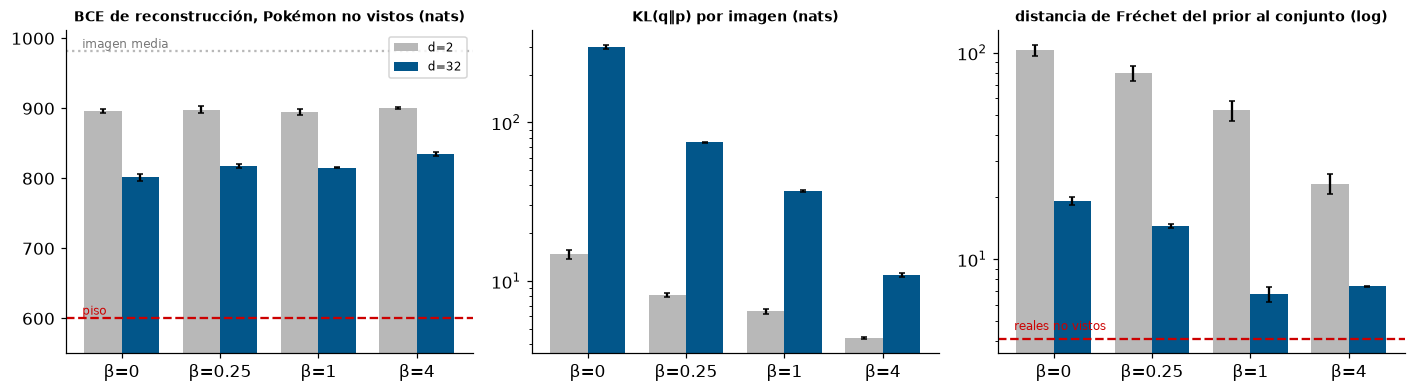

In [5]:
colD = {2: GRIS, 32: AZUL}; betas = sorted(db.beta.unique())
fig, axs = plt.subplots(1, 3, figsize=(13, 3.7))
for ax, (cc, tit, log) in zip(axs, [("rec_val", "BCE de reconstrucción, Pokémon no vistos (nats)", False),
                                    ("kl", "KL(q‖p) por imagen (nats)", True),
                                    ("fd", "distancia de Fréchet del prior al conjunto (log)", True)]):
    for k, dd in enumerate(c["latentes"]):
        g = db[db.latent == dd].groupby("beta")[cc]
        ax.bar(np.arange(len(betas)) + (k - .5) * .38, g.mean().values, .38, yerr=g.std().values, color=colD[dd], capsize=2, label=f"d={dd}")
    ax.set_xticks(range(len(betas))); ax.set_xticklabels([f"β={b:g}" for b in betas]); ax.set_title(tit, fontsize=9)
    if log: ax.set_yscale("log")
axs[0].axhline(piso, color=ROJO, ls="--"); axs[0].axhline(techo, color=GRIS, ls=":")
axs[0].set_ylim(piso - 50, techo + 30); axs[0].text(-.4, piso + 5, "piso", color=ROJO, fontsize=8); axs[0].text(-.4, techo + 5, "imagen media", color="#777", fontsize=8)
axs[2].axhline(fd_ref, color=ROJO, ls="--"); axs[2].text(-.4, fd_ref * 1.1, "reales no vistos", color=ROJO, fontsize=8)
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Lectura** (medias de 3 semillas; `results/ej2p_barrido.json`).
1. **El KL ordena el espacio latente.** Con $d=32$ y $\beta=0$ los códigos se dispersan (desvío de $\mu$ ≈ 2,6) y el KL, que se mide aunque no se optimice, llega a 299 nats por imagen. Con $\beta=1$ baja a 37 nats y el desvío a ≈ 1,0, que es justo la escala del prior $\mathcal{N}(0,I)$.
2. **Eso es lo que permite generar.** La distancia de Fréchet de las muestras del prior cae de 19,1 ($\beta=0$) a **6,8** ($\beta=1$), cerca del piso de 4,1 que da un Pokémon real no visto. Con $d=2$ pasa lo mismo en otra escala (103 → 53).
3. **El costo es la reconstrucción.** Con $d=32$ la BCE en Pokémon no vistos sube de 802 ($\beta=0$) a 815 ($\beta=1$) y a 835 ($\beta=4$), sobre un piso de 600 y un techo de 981 (imagen media).
4. **$\beta=1$ es el equilibrio.** $\beta=4$ tiene la mejor −ELBO de validación (849 contra 862: regulariza más y sobreajusta menos), pero no mejora las muestras (Fréchet 7,4 contra 6,8) y multiplica por 9 las casi copias (9 % contra 1 %): con un posterior tan pegado al prior, el decodificador usa menos información del código y sus muestras se parecen más a sprites existentes.
5. **$d=2$ no alcanza para dibujar.** La BCE de reconstrucción queda en ≈ 895 para cualquier $\beta$, más cerca de la imagen media (981) que del piso (600). Dos números no alcanzan para describir 728 Pokémon distintos; con las 32 letras del ejercicio 1 sí alcanzaban.

## 4. Espacio latente en 2 dimensiones: VAE ($\beta=1$) frente a autoencoder ($\beta=0$)

Los modelos finales usan la semilla 0. Si `correr_ej2_pokemon.py` ya los guardó en `results/`, se cargan; si no, se entrenan.

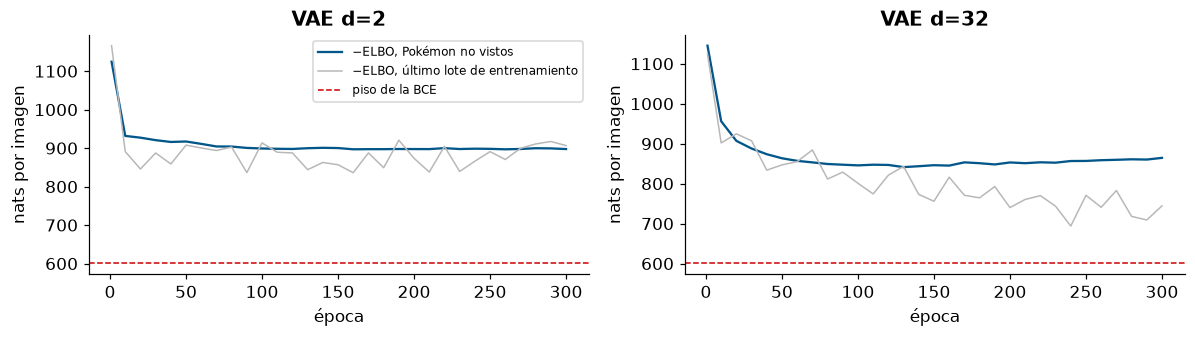

In [6]:
v2, h2 = vae_pokemon(P, cfg, 1.0, 2, RES)        # VAE  d=2
a2, _ = vae_pokemon(P, cfg, 0.0, 2, RES)         # AE   d=2  (β=0)
vG, hG = vae_pokemon(P, cfg, 1.0, 32, RES)       # VAE  d=32
aG, _ = vae_pokemon(P, cfg, 0.0, 32, RES)        # AE   d=32 (β=0)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, h, tit in [(axs[0], h2, "VAE d=2"), (axs[1], hG, "VAE d=32")]:
    h = pd.DataFrame(h)
    ax.plot(h.epoch, h.val_elbo, color=AZUL, label="−ELBO, Pokémon no vistos"); ax.plot(h.epoch, h.loss, color=GRIS, lw=1, label="−ELBO, último lote de entrenamiento")
    ax.axhline(piso, color=ROJO, ls="--", lw=1, label="piso de la BCE"); ax.set_title(tit); ax.set_xlabel("época"); ax.set_ylabel("nats por imagen")
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

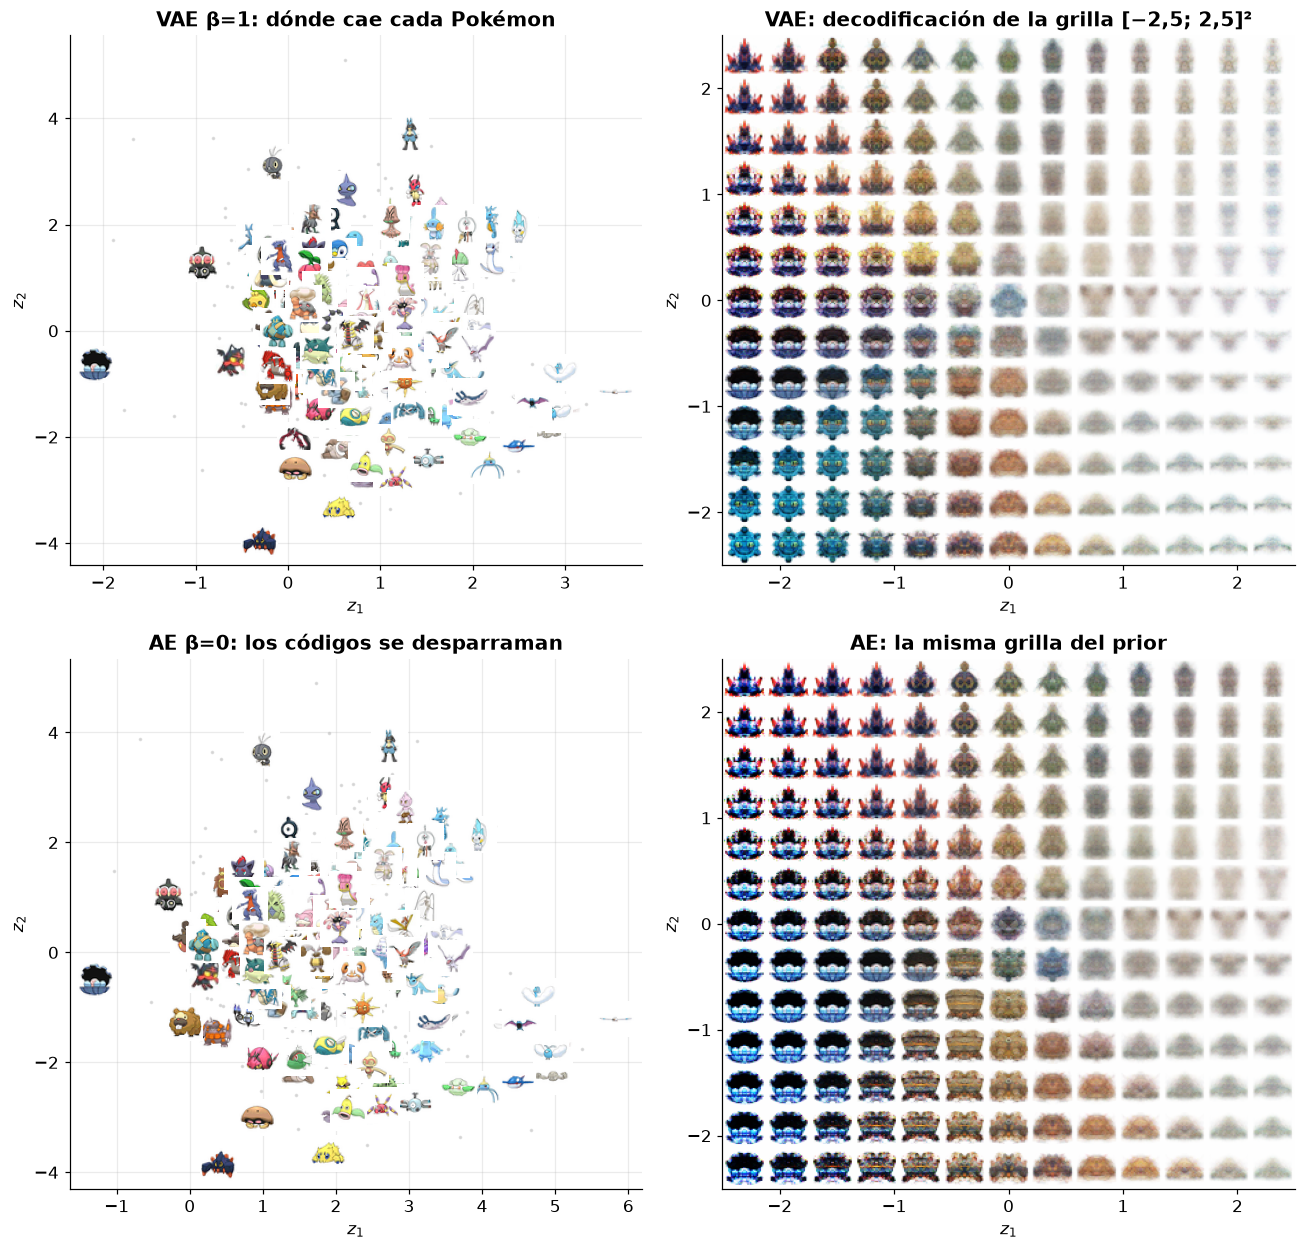

desvío de los códigos: VAE [0.75 1.24] | AE [1.02 1.29]
rango de los códigos:  VAE [-4.0, 5.1] | AE [-3.9, 5.8]
fracción de códigos dentro de [−2,5; 2,5]²: VAE 0.92 | AE 0.74


In [7]:
n_orig = len(P["tr"])                            # las primeras n_orig filas de Xtr son los sprites sin espejar
Xo = P["Xtr"][:n_orig]
mu2, _ = v2.encode(Xo); mu2a, _ = a2.encode(Xo)
fig, axs = plt.subplots(2, 2, figsize=(12, 11.5))
miniaturas_latente(mu2, Xo, S, axs[0, 0], zoom=.75, n_max=220); axs[0, 0].set_title("VAE β=1: dónde cae cada Pokémon")
grilla_decodificada(v2.decode, S, lim=2.5, n=13, ax=axs[0, 1]); axs[0, 1].set_title("VAE: decodificación de la grilla [−2,5; 2,5]²")
miniaturas_latente(mu2a, Xo, S, axs[1, 0], zoom=.75, n_max=220); axs[1, 0].set_title("AE β=0: los códigos se desparraman")
grilla_decodificada(a2.decode, S, lim=2.5, n=13, ax=axs[1, 1]); axs[1, 1].set_title("AE: la misma grilla del prior")
plt.tight_layout(); plt.show()
print(f"desvío de los códigos: VAE {mu2.std(0).round(2)} | AE {mu2a.std(0).round(2)}")
print(f"rango de los códigos:  VAE [{mu2.min():.1f}, {mu2.max():.1f}] | AE [{mu2a.min():.1f}, {mu2a.max():.1f}]")
print(f"fracción de códigos dentro de [−2,5; 2,5]²: VAE {(np.abs(mu2) < 2.5).all(1).mean():.2f} | AE {(np.abs(mu2a) < 2.5).all(1).mean():.2f}")

**Qué mirar.**
- **El VAE organiza el espacio sin etiquetas.** En la grilla decodificada, a la izquierda quedan las figuras oscuras y azules, en el centro las marrones y a la derecha las pálidas. Arriba quedan las figuras altas y con puntas, abajo las anchas y bajas. Las transiciones son suaves en todo el cuadrado $[-2{,}5;\,2{,}5]^2$.
- **El AE deja más códigos fuera del prior** (74 % dentro del cuadrado contra 92 % del VAE) y **asigna regiones grandes a un solo dato:** toda la esquina inferior izquierda de su grilla repite el mismo sprite oscuro (el código aislado cerca de $(-1{,}3;\,-0{,}5)$). Muestrear ahí devuelve siempre ese Pokémon.
- **En $d=2$ la diferencia de dispersión es menor que en el ejercicio 1,** porque con 300 épocas y lr bajo el AE no llega a separar mucho los códigos. La diferencia se ve más clara en la calidad de las muestras (Fréchet 46 contra 109, §5) y, sobre todo, con $d=32$.

### 4.1 Reconstrucción de Pokémon que el modelo nunca vio ($d=32$)

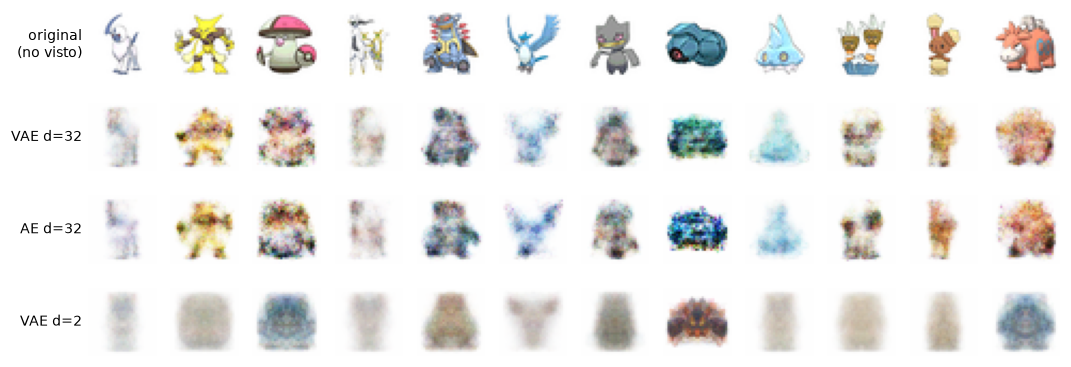

['absol', 'alakazam', 'amoonguss', 'arceus', 'armaldo', 'articuno', 'banette', 'beldum', 'bergmite', 'binacle', 'buneary', 'camerupt']


In [8]:
sel = np.arange(12)
Xv = P["Xte"][sel]
fig = fila_comparada([Xv, vG.reconstruct(Xv), aG.reconstruct(Xv), v2.reconstruct(Xv)],
                     ["original\n(no visto)", "VAE d=32", "AE d=32", "VAE d=2"], S, tam=.95)
plt.show(); print([nombres[i] for i in P["te"][sel]])

Con $d=32$ el VAE y el AE recuperan la **silueta y la paleta** de Pokémon que nunca vieron (el amarillo de Alakazam, el celeste de Articuno, la forma redonda de Beldum), pero no los detalles: ojos y contornos se pierden en una textura borrosa. Con $d=2$ sólo queda una mancha del color dominante.

## 5. Generación de Pokémon nuevos (consigna 2c)

Muestreamos $z\sim\mathcal{N}(0,I)$ y decodificamos. Si el espacio latente quedó bien regularizado, **cualquier** punto del prior tiene que dar algo con forma de Pokémon, y no sólo los puntos cercanos a un código de entrenamiento.

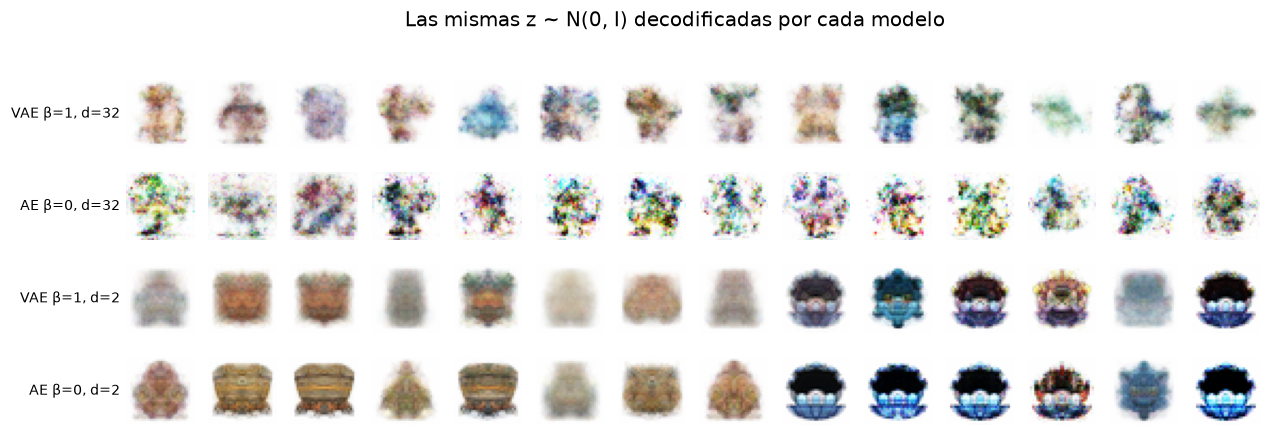

VAE d=32: Fréchet     7.4 (piso 4.1) | distancia mediana al vecino 8.2 (real no visto 9.7) | copias 0.008
AE  d=32: Fréchet    18.6 (piso 4.1) | distancia mediana al vecino 11.9 (real no visto 9.7) | copias 0.000


VAE d=2 : Fréchet    46.4 (piso 4.1) | distancia mediana al vecino 7.4 (real no visto 9.7) | copias 0.072
AE  d=2 : Fréchet   109.0 (piso 4.1) | distancia mediana al vecino 8.0 (real no visto 9.7) | copias 0.015


In [9]:
rng = np.random.default_rng(7)
Z2, ZG = rng.standard_normal((14, 2)), rng.standard_normal((14, 32))
fig = fila_comparada([vG.decode(ZG), aG.decode(ZG), v2.decode(Z2), a2.decode(Z2)],
                     ["VAE β=1, d=32", "AE β=0, d=32", "VAE β=1, d=2", "AE β=0, d=2"], S, tam=.95)
plt.suptitle("Las mismas z ~ N(0, I) decodificadas por cada modelo", y=1.02); plt.show()
rasgos = base_pca(P["Xtr"], c["componentes_pca"])
for nom, m in [("VAE d=32", vG), ("AE  d=32", aG), ("VAE d=2 ", v2), ("AE  d=2 ", a2)]:
    q = calidad_pokemon(m, P, cfg, rasgos=rasgos)
    print(f"{nom}: Fréchet {q['fd']:7.1f} (piso {q['fd_ref']:.1f}) | distancia mediana al vecino {q['d_gen_med']:.1f} (real no visto {q['d_real_med']:.1f}) | copias {q['frac_copia']:.3f}")

**Lectura.** Con las mismas $z$, el **AE con $d=32$ produce ruido de colores**: sus códigos de entrenamiento tienen desvío ≈ 2,6 y 299 nats de KL, así que $\mathcal{N}(0,I)$ cae en regiones que su decodificador nunca vio. Es el problema de los huecos del ejercicio 1, ahora en 32 dimensiones. El **VAE** produce figuras centradas sobre fondo blanco, con colores coherentes y siluetas de criatura (Fréchet 7,4 contra 18,6 del AE; piso 4,1), y menos del 1 % son casi copias. Con $d=2$ las muestras son manchas suaves: el cuello de botella limita la nitidez.

### 5.1 ¿Las muestras tienen la forma de un sprite?
Una comprobación que no depende de ninguna métrica aprendida: un sprite es **una figura sobre fondo blanco**. Comparamos la distribución del área ocupada (fracción de píxeles que no son fondo) y del color medio de la figura entre los Pokémon reales y 2000 muestras de cada modelo.

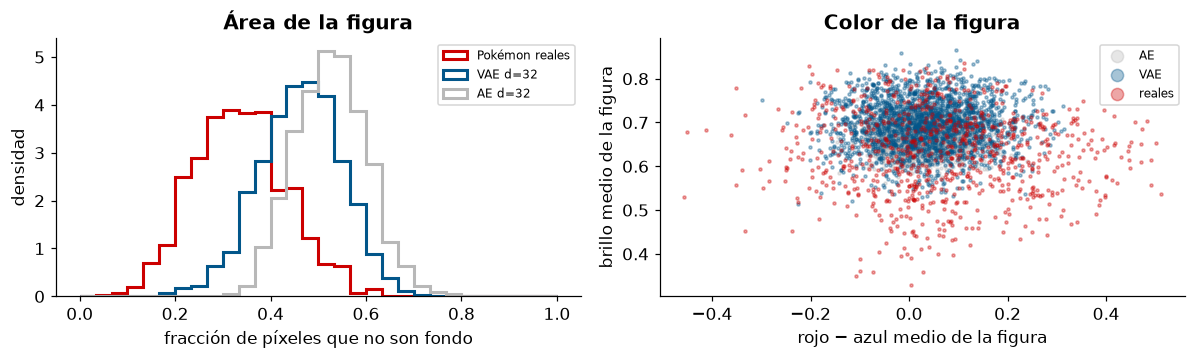

reales  área media 0.34 (desvío 0.10)
VAE     área media 0.46 (desvío 0.09)
AE      área media 0.53 (desvío 0.07)


In [10]:
def area(X): return ((X.reshape(len(X), -1, 3)).min(2) < 0.9).mean(1)
def color_figura(X):
    R = X.reshape(len(X), -1, 3); m = R.min(2) < 0.9
    return np.array([R[i][m[i]].mean(0) if m[i].any() else np.ones(3) for i in range(len(X))])
Zm = np.random.default_rng(3).standard_normal((2000, 32)); GV, GA = vG.decode(Zm), aG.decode(Zm)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
bins = np.linspace(0, 1, 31)
for X_, col, lab in [(P["X"], ROJO, "Pokémon reales"), (GV, AZUL, "VAE d=32"), (GA, GRIS, "AE d=32")]:
    axs[0].hist(area(X_), bins, density=True, histtype="step", lw=2, color=col, label=lab)
axs[0].set_xlabel("fracción de píxeles que no son fondo"); axs[0].set_ylabel("densidad"); axs[0].legend(fontsize=8); axs[0].set_title("Área de la figura")
for X_, col, lab in [(GA, GRIS, "AE"), (GV, AZUL, "VAE"), (P["X"], ROJO, "reales")]:
    C = color_figura(X_); axs[1].scatter(C[:, 0] - C[:, 2], C.mean(1), s=4, alpha=.35, color=col, label=lab)
axs[1].set_xlabel("rojo − azul medio de la figura"); axs[1].set_ylabel("brillo medio de la figura"); axs[1].legend(fontsize=8, markerscale=4); axs[1].set_title("Color de la figura")
plt.tight_layout(); plt.show()
for nom, X_ in [("reales", P["X"]), ("VAE", GV), ("AE", GA)]:
    a = area(X_); print(f"{nom:7s} área media {a.mean():.2f} (desvío {a.std():.2f})")

Las muestras del VAE están más cerca de los sprites reales que las del AE, pero ninguna coincide del todo. Ocupan **más área** (0,46 contra 0,34 de los reales, AE 0,53), porque el borde borroso cuenta como figura, y sus colores se concentran en el centro del plano: el VAE **promedia paletas** y genera figuras menos saturadas que los Pokémon reales. Las dos cosas son la conocida borrosidad del VAE con verosimilitud factorizada por píxel (Doersch, 2016, §2.1).

### 5.2 Elegir una muestra nueva y justificar que pertenece al conjunto
Un criterio ingenuo, quedarse con las muestras más cercanas a un dato en distancia de píxeles, favorece imágenes **pálidas y casi vacías**: una imagen casi blanca queda cerca de cualquier sprite claro. Por eso usamos propiedades de sprite como filtro y medimos la cercanía en el **espacio PCA**, que captura la estructura global (silueta y color) y no cada píxel.

Entre las 2000 muestras del prior del VAE ($d=32$) se retienen las que:
1. **no son copias:** su vecino de entrenamiento más cercano en píxeles está a más de la mitad de la distancia típica de un Pokémon real no visto;
2. **tienen área y contraste de sprite:** la fracción de píxeles de figura y el desvío de color de la figura caen entre los percentiles 10 y 90 de los Pokémon reales. Así se descartan las manchas pálidas y las figuras que llenan el cuadro.

Después se ordenan por distancia al vecino de entrenamiento más cercano en el espacio PCA. Se muestran las 10 primeras, con vecinos distintos, al lado de ese vecino.

629 de 2000 muestras no son copias y tienen área y contraste de sprite real
distancia mediana al vecino de entrenamiento en el espacio PCA: muestras filtradas 4.56 | Pokémon reales no vistos 4.54


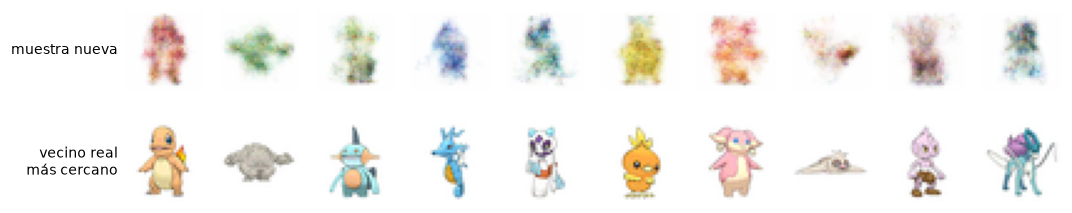

vecinos: ['charmander', 'graveler (esp.)', 'marshtomp', 'kingdra', 'froslass', 'torchic (esp.)', 'audino (esp.)', 'slakoth (esp.)', 'tyrogue (esp.)', 'suicune (esp.)']


In [11]:
def contraste(X):
    R = X.reshape(len(X), -1, 3); m = R.min(2) < 0.9
    return np.array([R[i][m[i]].std() if m[i].sum() > 5 else 0.0 for i in range(len(X))])
en_rango = lambda v, ref: (v >= np.percentile(ref, 10)) & (v <= np.percentile(ref, 90))
Gc = GV
dn = dist_vecino(Gc, P["Xtr"]); med = np.median(dist_vecino(P["Xte"], P["Xtr"]))
ok = np.where((dn > 0.5 * med) & en_rango(area(Gc), area(P["X"])) & en_rango(contraste(Gc), contraste(P["X"])))[0]
Ftr, Fg = rasgos(P["Xtr"]), rasgos(Gc)
dpca, dpca_real = dist_vecino(Fg, Ftr), np.median(dist_vecino(rasgos(P["Xte"]), Ftr))
print(f"{len(ok)} de {len(Gc)} muestras no son copias y tienen área y contraste de sprite real")
print(f"distancia mediana al vecino de entrenamiento en el espacio PCA: muestras filtradas {np.median(dpca[ok]):.2f} | Pokémon reales no vistos {dpca_real:.2f}")
nombre_tr = lambda j: nombres[P["tr"][j % n_orig]] + (" (esp.)" if j >= n_orig else "")
vec = lambda i: int(np.argmin(((Ftr - Fg[i]) ** 2).sum(1)))
elegidos, usados = [], set()
for i in ok[np.argsort(dpca[ok])]:
    n = nombres[P["tr"][vec(i) % n_orig]]
    if n not in usados: elegidos.append(i); usados.add(n)
    if len(elegidos) == 10: break
vecinos = [vec(i) for i in elegidos]
fig = fila_comparada([Gc[elegidos], P["Xtr"][vecinos]], ["muestra nueva", "vecino real\nmás cercano"], S, tam=1.1); plt.show()
print("vecinos:", [nombre_tr(j) for j in vecinos])

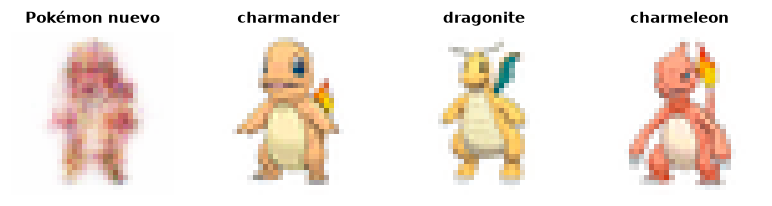

en píxeles: vecino más cercano a 6.1 (umbral de copia 4.9; un Pokémon real no visto, mediana 9.7)
en el espacio PCA: vecino más cercano a 2.82 (un Pokémon real no visto, mediana 4.54)


área de la figura 0.37 y contraste 0.171 (reales: mediana 0.33 y 0.200)


In [12]:
# Muestra elegida a ojo entre las de arriba, junto a sus tres vecinos reales más cercanos (espacio PCA, nombres distintos).
ELEGIDA = 0
i = elegidos[ELEGIDA]; g = Gc[i]
d_f = np.sqrt(((Ftr - Fg[i]) ** 2).sum(1)); cerca = []
for j in np.argsort(d_f):
    if nombres[P["tr"][j % n_orig]] not in [nombres[P["tr"][k % n_orig]] for k in cerca]: cerca.append(j)
    if len(cerca) == 3: break
fig = mostrar_imagenes(np.array([g] + [P["Xtr"][j] for j in cerca]), S,
                       ["Pokémon nuevo"] + [nombre_tr(j) for j in cerca], ncols=4, tam=2.2, ax_title_size=10)
plt.show()
print(f"en píxeles: vecino más cercano a {dn[i]:.1f} (umbral de copia {0.5 * med:.1f}; un Pokémon real no visto, mediana {med:.1f})")
print(f"en el espacio PCA: vecino más cercano a {dpca[i]:.2f} (un Pokémon real no visto, mediana {dpca_real:.2f})")
print(f"área de la figura {area(g[None])[0]:.2f} y contraste {contraste(g[None])[0]:.3f} (reales: mediana {np.median(area(P['X'])):.2f} y {np.median(contraste(P['X'])):.3f})")

**¿Pertenece al conjunto?** La muestra elegida es una **criatura bípeda rojiza, de panza clara, parada de frente**: el esquema de un inicial de fuego. Sus vecinos más cercanos son Charmander, Dragonite y Charmeleon, y no es ninguno de ellos. Los argumentos son:
- **No es una copia:** en píxeles está a 6,1 de su vecino más cercano, por encima del umbral de copia (4,9).
- **Está tan cerca del conjunto como un Pokémon real:** en el espacio PCA queda a 2,82 de su vecino, contra una mediana de 4,54 para los Pokémon reales no vistos.
- **Tiene área y contraste de sprite real** (0,37 y 0,171, contra medianas de 0,33 y 0,200).
- **El grupo filtrado, en conjunto, es indistinguible de Pokémon reales nuevos en esa escala:** mediana de 4,56 en PCA contra 4,54.

El juicio final sigue siendo humano. La figura se reconoce como Pokémon por silueta y paleta, no por detalles (no tiene ojos ni contornos nítidos).

### 5.3 Interpolaciones en el espacio latente
Interpolamos linealmente entre los códigos $\mu$ de dos Pokémon ($d=32$). Si el espacio latente es continuo y no tiene huecos, el camino pasa por figuras intermedias plausibles y no por ruido. Usamos el VAE y, como contraste, el autoencoder con $\beta=0$.

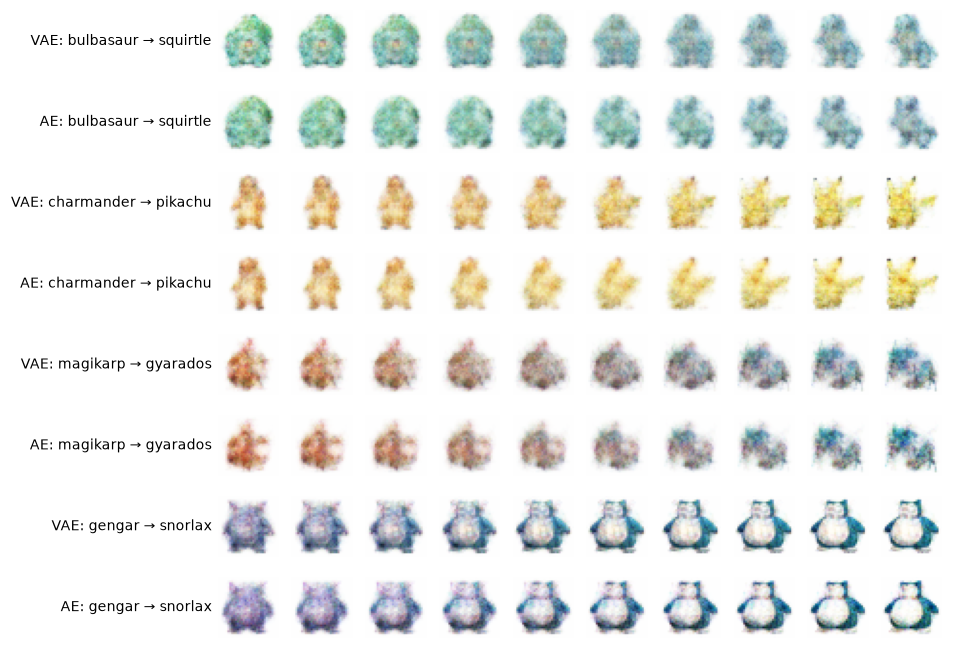

In [13]:
pares = [("bulbasaur", "squirtle"), ("charmander", "pikachu"), ("magikarp", "gyarados"), ("gengar", "snorlax")]
X_por_nombre = {n: P["X"][i] for i, n in enumerate(nombres)}
ts = np.linspace(0, 1, 10)
filas, nom = [], []
for a, b in pares:
    for m, tag in [(vG, "VAE"), (aG, "AE")]:
        za, zb = m.encode(np.array([X_por_nombre[a], X_por_nombre[b]]))[0]
        filas.append(m.decode(np.array([(1 - t) * za + t * zb for t in ts]))); nom.append(f"{tag}: {a} → {b}")
fig = fila_comparada(filas, nom, S, tam=.85); plt.show()

Las dos familias de caminos son suaves (Charmander pasa por un intermedio anaranjado antes de ser Pikachu; Gengar se infla hasta Snorlax), **también en el AE**. Interpolar entre dos códigos de entrenamiento no distingue los modelos, porque los dos conocen la región entre sus datos, igual que en el ejercicio 1 la letra nueva era legible cerca de los códigos. La diferencia aparece al **muestrear del prior** (§5): ahí el AE cae en huecos y el VAE no.

## 6. Conclusiones y limitaciones
1. **El término KL es lo que vuelve muestreable al espacio latente.** Con $d=32$ y la misma arquitectura y los mismos datos, las muestras de $\mathcal{N}(0,I)$ del VAE ($\beta=1$) quedan a una distancia de Fréchet de 6,8 ± 0,6 del conjunto, cerca del piso de 4,1 de un Pokémon real no visto. El autoencoder ($\beta=0$) queda en 19,1 y genera ruido, porque sus códigos no viven donde el prior pone su masa (KL de 299 nats). Esto resuelve el problema de los huecos que dejó el ejercicio 1.
2. **El precio es reconstruir un poco peor** (815 contra 802 nats en Pokémon no vistos). $\beta=1$ es el equilibrio: $\beta=4$ generaliza mejor en ELBO, pero no mejora las muestras y produce 9 % de casi copias.
3. **El espacio de 2 dimensiones se organiza solo** por color y silueta, sin etiquetas, pero no alcanza para dibujar 728 Pokémon distintos: reconstruye cerca de la imagen media.
4. **Generación (2c):** de 2000 muestras del prior, 629 no son copias y tienen área y contraste de sprite real, y su distancia al conjunto en el espacio PCA es la de un Pokémon real nuevo (4,56 contra 4,54). La elegida, una criatura bípeda roja parecida a los iniciales de fuego, no es ninguno de los 809.
5. **Interpolar no alcanza para comparar modelos:** entre dos códigos de entrenamiento el AE también interpola bien. La prueba de un modelo generativo es muestrear del prior.
6. **Limitaciones.**
   - Las muestras son **borrosas** y de colores apagados. Es una consecuencia de la verosimilitud factorizada por píxel y de usar una MLP en lugar de una red convolucional.
   - Hay sólo 728 Pokémon de entrenamiento (1456 con espejados) a 32×32.
   - La distancia de Fréchet se calcula sobre 20 componentes principales: es un sustituto grueso del FID, que usa rasgos de una red preentrenada.
   - El filtro de selección (área, contraste, cercanía en PCA) es una heurística.
   - Hay 3 semillas por celda y sólo una partición de validación.

   **Extensiones naturales:** un VAE convolucional, más sprites por Pokémon (otros ángulos y generaciones) o una pérdida perceptual.